# EDA відгуків з Google Play

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from langdetect import DetectorFactory, detect
from langdetect.lang_detect_exception import LangDetectException

DetectorFactory.seed = 0
pd.set_option("display.max_colwidth", 150)

In [2]:
data_path = sorted(Path("../data/raw").glob("google_play_*.csv"))[-1]
df = pd.read_csv(data_path, parse_dates=["at"])

print(data_path.name, df.shape)
print("Period:", df["at"].min().date(), "-", df["at"].max().date())
print("Median length:", int(df["content"].str.len().median()), "chars")
print("Short (<20 chars):", round((df["content"].str.len() < 20).mean() * 100, 1), "%")
df["app"].value_counts()

google_play_20261018.csv (10499, 11)
Period: 2021-12-22 - 2026-10-17
Median length: 58 chars
Short (<20 chars): 25.4 %


app
privat24       1500
nova_poshta    1500
rozetka        1500
olx            1500
glovo          1500
bolt           1500
monobank       1499
Name: count, dtype: int64

## Мова

In [3]:
UA_LETTERS = set("іїєґІЇЄҐ")
RU_LETTERS = set("ыэёъЫЭЁЪ")


def detect_lang(text):
    if not any(ch.isalpha() for ch in text):
        return "no_letters"
    has_ua = any(ch in UA_LETTERS for ch in text)
    has_ru = any(ch in RU_LETTERS for ch in text)
    if has_ua and has_ru:
        return "mixed"
    if has_ua:
        return "uk"
    if has_ru:
        return "ru"
    try:
        lang = detect(text)
    except LangDetectException:
        return "unknown"
    return lang if lang in {"uk", "ru", "en"} else "other"


df["lang"] = df["content"].astype(str).map(detect_lang)
df["lang"].value_counts(normalize=True).round(3)

lang
uk            0.462
ru            0.291
other         0.117
en            0.109
no_letters    0.017
mixed         0.005
unknown       0.000
Name: proportion, dtype: float64

In [4]:
pd.crosstab(df["request_lang"], df["lang"], normalize="index").round(2)

lang,en,mixed,no_letters,other,ru,uk,unknown
request_lang,,,,,,,
en,0.30,0.00,0.01,0.17,0.12,0.40,0.0
ru,0.01,0.01,0.02,0.10,0.61,0.25,0.0
uk,0.01,0.00,0.02,0.08,0.15,0.74,0.0


## Оцінки і довжина

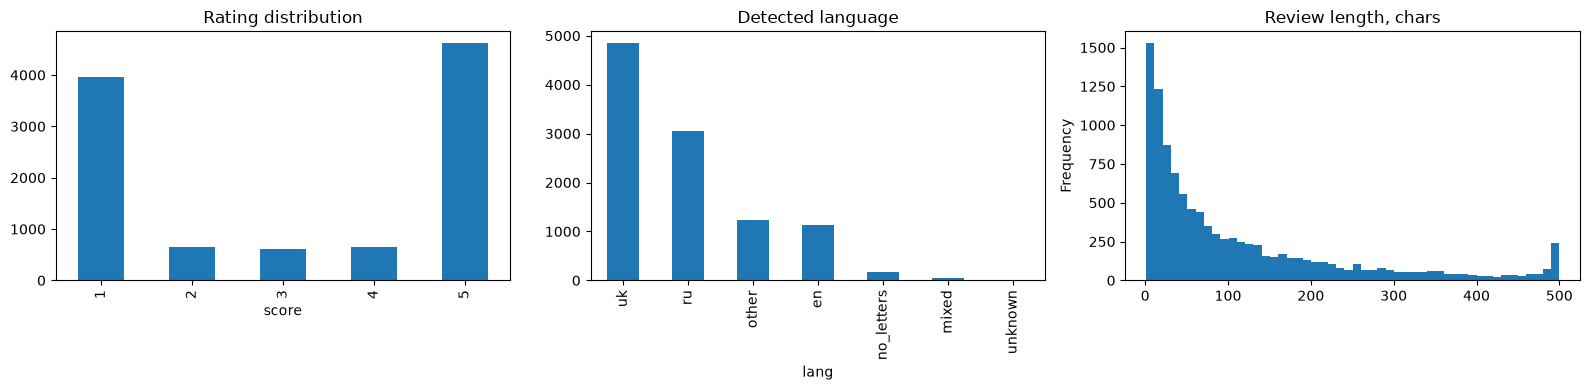

In [5]:
df["sentiment"] = df["score"].map(
    {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["score"].value_counts().sort_index().plot.bar(ax=axes[0], title="Rating distribution")
df["lang"].value_counts().plot.bar(ax=axes[1], title="Detected language")
df["content"].str.len().clip(upper=500).plot.hist(bins=50, ax=axes[2], title="Review length, chars")
plt.tight_layout()
plt.show()

In [7]:
df[df["sentiment"] == "negative"].sample(10, random_state=42)[["app", "score", "lang", "content"]]

,app,score,lang,content
9428,bolt,1,other,Serwis zero.Korzystam z tej aplikacji miesiąc.Zawsze nie mogą trafić na adres zamieszkania.Pszyjechał nie na zadany adres.U mnie za każdym razem p...
1165,monobank,1,uk,"мене обманули по нових умовах договору, не можу більше довіряти цьому банку"
9380,bolt,1,uk,"Чому не можна залишити самокат в зоні, яка є житловим мікрорайоном і в якій є багато користувачів самокатів? Ще й штраф 200грн! Штраф мені за те, ..."
178,monobank,1,uk,"щоб оно́вити вашу програму, я маю видалити інші дода́тки на своєму телефоні??!!(( То мені не цікаві ваші оновлення, мій телефон від цього новішою ..."
8292,glovo,1,ru,"В чате поддержки невозможно получить никакую помощь, т.к. курьеры работают ужасно. Наводящие ответы и вопросы, никто не выходит на связь. Сделайте..."
3668,nova_poshta,1,ru,"Разрабы, вышла из аккаунта, войти не могу. На этапе ввода пароля - бесконечное ожидание, дальше не пускает! Пароль, естественно, правильный. Пробо..."
4063,nova_poshta,1,ru,"Стало дорого, да еще коробку тебе больше продадут. Дерут деньги за все, а за сохранность не отвечают. Да еще с тебя деньги дерут, мол если мы побь..."
3009,nova_poshta,1,uk,Перестали показувати в якому місті посилка. Рівень нижче Укрпошти за більші гроші. Потрібно переходити на інших перевізників.
6746,olx,1,ru,"Наверное самое худшее приложение для заказов товаров и т.д. просто ужас... после обновления перестало работать нормально, ничего не находило, пыта..."
9242,bolt,1,uk,"сервіс жахливий, пише - водій є, потім - водіїв немає, і знімає кошти, невже не можна знімати кошти після підтвердження? додано на відповідь: напи..."


## Висновки

- оцінки в основному 1 або 5, трійок всього ~6%, тому нейтральний клас буде дуже маленький
- параметру lang у google-play-scraper вірити не можна: в запитах з lang=en українських відгуків навіть більше, ніж англійських (40% проти 30%). Мову треба визначати самому
- загалом українською ~46%, російською ~29%, англійською ~11%
- ~12% пішло в other, частина реально польська і т.д., але схоже langdetect ще й плутається на коротких текстах, треба спробувати інші детектори
- чверть відгуків коротші за 20 символів ("супер", "отлично"), для тем вони майже нічого не дають
- суржику (mixed) мало, але він є
- негативу ~44%, для тематичного моделювання цього вистачить